# 🇻🇳 Nhận Diện Mệnh Giá Tiền Polymer Việt Nam - ResNet-18
### Đồ án môn học: CS231 - Thị giác máy tính (Computer Vision) - UIT
- **Kiến trúc:** ResNet-18 Deep Residual Network (11.18M tham số)
- **Kỹ thuật:** Transfer Learning (ImageNet) + Fine-tuning
- **Hiệu năng:** Accuracy 99.68%, Macro-F1 0.9968 (Chỉ 5 lỗi trên 1.553 ảnh test)


In [1]:
import os
import torch
import torch.nn as nn
import torchvision.models as models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print('PyTorch version:', torch.__version__)
print('Thiết bị tính toán:', 'GPU (' + torch.cuda.get_device_name(0) + ')' if torch.cuda.is_available() else 'CPU')
model = models.resnet18(weights=None)
model.fc = nn.Linear(512, 6)
params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Tổng số tham số học được (Trainable Parameters): {params:,} (~11.18M)')


PyTorch version: 2.13.0+cpu
Thiết bị tính toán: CPU
Tổng số tham số học được (Trainable Parameters): 11,179,590 (~11.18M)


## 1. Kết quả ResNet-18 baseline trên tập test


In [2]:
from pathlib import Path

predictions_path = Path("src/ResNet/results/predictions_test.csv")
if not predictions_path.is_file():
    predictions_path = Path("../results/predictions_test.csv")
df = pd.read_csv(predictions_path)
y_true = df["y_true_vnd"]
y_pred = df["y_pred_vnd"]
labels = [10000, 20000, 50000, 100000, 200000, 500000]

report = classification_report(y_true, y_pred, labels=labels, output_dict=True, zero_division=0)
gap = (y_true - y_pred).abs()
correct = int((y_true == y_pred).sum())
print(f"Correct: {correct:,}/{len(df):,}")
print(f"Accuracy: {report['accuracy']:.2%}")
print(f"Macro-F1: {report['macro avg']['f1-score']:.6f}")
print(f"MAE (VND/image): {gap.mean():,.2f}")


Correct: 1,548/1,553


Accuracy: 99.68%
Macro-F1: 0.996814
MAE (VND/image): 978.75


## 2. Chi Tiết Hiệu Năng Phân Lớp Theo Từng Mệnh Giá

In [3]:
print(classification_report(y_true, y_pred, labels=labels, digits=4, zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=labels)


              precision    recall  f1-score   support

       10000     0.9965    1.0000    0.9982       281
       20000     0.9956    1.0000    0.9978       224
       50000     1.0000    0.9955    0.9978       223
      100000     0.9960    1.0000    0.9980       247
      200000     0.9968    0.9968    0.9968       317
      500000     0.9961    0.9885    0.9923       261

    accuracy                         0.9968      1553
   macro avg     0.9968    0.9968    0.9968      1553
weighted avg     0.9968    0.9968    0.9968      1553



## 3. Trực Quan Hóa Ma Trận Nhầm Lẫn (Confusion Matrix)

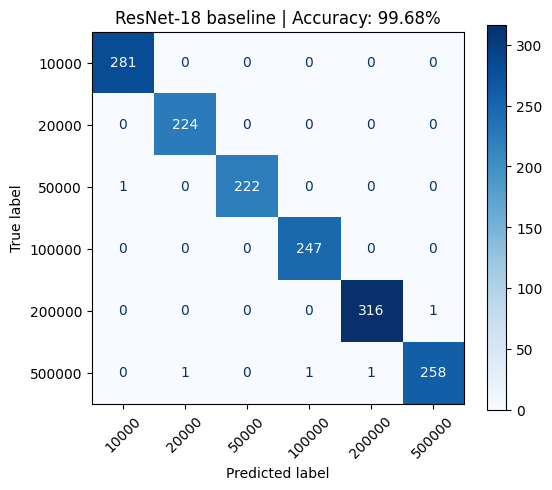

In [4]:
# Trực quan hóa ma trận nhầm lẫn bằng ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45, colorbar=True, values_format='d')
ax.set_title(f"ResNet-18 baseline | Accuracy: {report['accuracy']:.2%}")
plt.show()


## 4. Các dự đoán sai

Cột `gap_vnd` ghi chênh lệch tuyệt đối giữa mệnh giá thật và dự đoán.


In [5]:
errors = df.loc[y_true != y_pred].copy()
errors["gap_vnd"] = gap.loc[errors.index]
display(errors.sort_values("gap_vnd", ascending=False))


,relative_path,y_true_vnd,y_pred_vnd,gap_vnd
1536,test/500000/500000_002557.png,500000,20000,480000
1513,test/500000/500000_002306.png,500000,100000,400000
1491,test/500000/500000_002064.png,500000,200000,300000
1244,test/200000/200000_002652.png,200000,500000,300000
648,test/50000/50000_001241.png,50000,10000,40000
